# Traffic Accidents: Data Collection and Exploration

**Course:** CSC17104 - Programming for Data Science  
**Group:** Group 14 - Tam Khuyen  

This notebook documents the dataset provenance, examines its structure and quality, performs shared baseline preprocessing, and identifies limitations and patterns that guide the project's analytical questions.

## 1. Data collection

### 1.1 Subject and real-world context

The dataset describes reported traffic crashes in Chicago. Each row represents one recorded crash and contains information about the crash time, traffic controls, weather and lighting, roadway conditions, collision type, reported cause, vehicle count, damage category, and injuries.

### 1.2 Source and provenance

- **Kaggle dataset:** [Traffic Accidents by Oktay Ordekci](https://www.kaggle.com/datasets/oktayrdeki/traffic-accidents)
- **Kaggle version used:** version 1, initial release, published 2025-01-20
- **Official source context:** [Traffic Crashes - Crashes, City of Chicago Data Portal](https://data.cityofchicago.org/Transportation/Traffic-Crashes-Crashes/85ca-t3if/about_data)
- **Original data owner:** Chicago Police Department; data provided by the City of Chicago
- **Local raw file:** `data/raw/traffic_accidents.csv`, extracted from `data/traffic_accidents.zip` when needed
- **Snapshot size:** 209,306 rows and 24 columns
- **Observed date range:** 2013-03-03 to 2025-01-18

The Kaggle page supplies the snapshot used by the group. The City of Chicago portal is used as the original-source context because the column definitions, category labels, and crash-reporting description align with the official `Traffic Crashes - Crashes` dataset. The Kaggle description does not document the complete transformation history, so the project records this relationship transparently instead of claiming that the local file is an unchanged official export.

### 1.3 License and attribution

Kaggle lists the snapshot license as **Other (specified in description)**. The description does not specify the reuse terms for the CSV, so permission to redistribute this exact snapshot remains unverified. The course approval covers use of the dataset for this project.

This notebook credits Oktay Ordekci for the Kaggle snapshot and the City of Chicago and its Police Department for the official source context. The [City of Chicago Data Terms of Use](https://www.chicago.gov/city/en/narr/foia/data_disclaimer.html) are a reference for the official city data. The analysis and all record counts refer to the Kaggle snapshot identified above.

### 1.4 Collection method and population

The official Chicago dataset is based on traffic-crash reports recorded in the Chicago Police Department's electronic crash-reporting system (E-Crash). Reports may be completed by responding officers at the scene or self-reported at a police district and can later be amended. The population represented is reported crashes on streets within Chicago city limits and CPD jurisdiction; crashes handled by another agency may be excluded.

### 1.5 Known limitations and potential biases

- Coverage before September 2017 is not citywide, and the 2025 data are only a partial year.
- Weather, lighting, road condition, and contributory cause may reflect the reporting officer's best available assessment.
- Some crashes are self-reported, which may create reporting differences.
- The dataset contains only reported crashes and no traffic-exposure denominator, so it cannot directly estimate a driver's probability of crashing.
- Missing information is often encoded as `UNKNOWN`, `NOT APPLICABLE`, or `UNABLE TO DETERMINE` instead of a conventional null value.
- This Kaggle extract lacks the official unique crash identifier and detailed location fields, limiting duplicate verification, record linkage, and spatial analysis.

### 1.6 Motivation

The dataset is large, real-world, and contains temporal, categorical, and injury-related variables. It supports reproducible data cleaning, statistical comparisons, uncertainty quantification, robustness checks, external-data merging, and a time-aware machine-learning task related to traffic safety.

### 1.7 Notebook setup

Run the notebook from the repository root or the `notebooks/` directory. On a fresh copy of the repository, the setup extracts `traffic_accidents.csv` from `data/traffic_accidents.zip` into `data/raw/`. If the raw CSV already exists, the notebook uses it directly. After validation, the notebook creates `data/processed/` and exports the shared cleaned CSV.

In [1]:
from pathlib import Path
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "traffic_accidents.csv"
RAW_ARCHIVE_PATH = PROJECT_ROOT / "data" / "traffic_accidents.zip"

if not RAW_DATA_PATH.is_file():
    if not RAW_ARCHIVE_PATH.is_file():
        raise FileNotFoundError(
            "Place traffic_accidents.csv in data/raw/ or traffic_accidents.zip in data/. "
            f"Looked under {PROJECT_ROOT}."
        )
    with ZipFile(RAW_ARCHIVE_PATH) as archive:
        archive.extract(RAW_DATA_PATH.name, path=RAW_DATA_PATH.parent)

df = pd.read_csv(RAW_DATA_PATH)

print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
df.head()

Number of rows: 209,306
Number of columns: 24


,crash_date,traffic_control_device,weather_condition,lighting_condition,first_crash_type,trafficway_type,alignment,roadway_surface_cond,road_defect,crash_type,intersection_related_i,damage,prim_contributory_cause,num_units,most_severe_injury,injuries_total,injuries_fatal,injuries_incapacitating,injuries_non_incapacitating,injuries_reported_not_evident,injuries_no_indication,crash_hour,crash_day_of_week,crash_month
0,07/29/2023 01:00:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,TURNING,NOT DIVIDED,STRAIGHT AND LEVEL,UNKNOWN,UNKNOWN,NO INJURY / DRIVE AWAY,Y,"$501 - $1,500",UNABLE TO DETERMINE,2,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,13,7,7
1,08/13/2023 12:11:00 AM,TRAFFIC SIGNAL,CLEAR,"DARKNESS, LIGHTED ROAD",TURNING,FOUR WAY,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,Y,"OVER $1,500",IMPROPER TURNING/NO SIGNAL,2,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,2.0,0,1,8
2,12/09/2021 10:30:00 AM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,REAR END,T-INTERSECTION,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,Y,"$501 - $1,500",FOLLOWING TOO CLOSELY,3,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,10,5,12
3,08/09/2023 07:55:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,ANGLE,FOUR WAY,STRAIGHT AND LEVEL,DRY,NO DEFECTS,INJURY AND / OR TOW DUE TO CRASH,Y,"OVER $1,500",UNABLE TO DETERMINE,2,NONINCAPACITATING INJURY,5.0,0.0,0.0,5.0,0.0,0.0,19,4,8
4,08/19/2023 02:55:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,REAR END,T-INTERSECTION,STRAIGHT AND LEVEL,UNKNOWN,UNKNOWN,NO INJURY / DRIVE AWAY,Y,"$501 - $1,500",DRIVING SKILLS/KNOWLEDGE/EXPERIENCE,2,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,14,7,8


## 2. Initial data inspection

This section examines the dataset structure, data types, missing values,
duplicates, placeholder values, and basic distributions before cleaning. Cleaning decisions are made only after the initial audit is documented.

### 2.1 Dataset overview and data dictionary

One row represents one recorded traffic crash. The table below summarizes the 24 raw columns before any conversion or feature engineering.

| Column | Meaning | Raw type |
|---|---|---|
| `crash_date` | Reported date and time of the crash | string |
| `traffic_control_device` | Traffic-control device present | string |
| `weather_condition` | Reported weather condition | string |
| `lighting_condition` | Reported lighting condition | string |
| `first_crash_type` | Type of the first collision | string |
| `trafficway_type` | Roadway or intersection configuration | string |
| `alignment` | Road alignment and grade | string |
| `roadway_surface_cond` | Reported road-surface condition | string |
| `road_defect` | Reported road defect | string |
| `crash_type` | Broad injury/tow or drive-away category | string |
| `intersection_related_i` | Whether the crash is intersection-related | string |
| `damage` | Estimated property-damage category | string |
| `prim_contributory_cause` | Primary reported contributory cause | string |
| `num_units` | Number of traffic units involved | integer |
| `most_severe_injury` | Most severe injury recorded in the crash | string |
| `injuries_total` | Total number of injured people | float representing a count |
| `injuries_fatal` | Number of fatal injuries | float representing a count |
| `injuries_incapacitating` | Number of incapacitating injuries | float representing a count |
| `injuries_non_incapacitating` | Number of non-incapacitating injuries | float representing a count |
| `injuries_reported_not_evident` | Number of reported injuries not visibly evident | float representing a count |
| `injuries_no_indication` | Number of people with no injury indication | float representing a count |
| `crash_hour` | Hour of day, from 0 to 23 | integer |
| `crash_day_of_week` | Day code, where Sunday is 1 and Saturday is 7 | integer |
| `crash_month` | Month number, from 1 to 12 | integer |

In [3]:
overview = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "non_null_count": df.notna().sum(),
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
    "unique_count": df.nunique(dropna=False)
})

display(overview)

,data_type,non_null_count,missing_count,missing_percentage,unique_count
crash_date,str,209306,0,0.0,189087
traffic_control_device,str,209306,0,0.0,19
weather_condition,str,209306,0,0.0,12
lighting_condition,str,209306,0,0.0,6
first_crash_type,str,209306,0,0.0,18
trafficway_type,str,209306,0,0.0,20
alignment,str,209306,0,0.0,6
roadway_surface_cond,str,209306,0,0.0,7
road_defect,str,209306,0,0.0,7
crash_type,str,209306,0,0.0,2


### 2.2 Duplicate and blank rows

Exact duplicate rows and empty strings are checked before cleaning. Duplicate removal is not automatic at this stage because the extract does not include a unique crash identifier; the number and proportion affected must first be reported.

In [4]:
duplicate_count = df.duplicated().sum()
duplicate_percentage = duplicate_count / len(df) * 100

print(f"Duplicated rows: {duplicate_count:,}")
print(f"Duplicated percentage: {duplicate_percentage:.4f}%")

Duplicated rows: 31
Duplicated percentage: 0.0148%


In [5]:
duplicate_rows = df[df.duplicated(keep=False)]

display(duplicate_rows.head(20))

,crash_date,traffic_control_device,weather_condition,lighting_condition,first_crash_type,trafficway_type,alignment,roadway_surface_cond,road_defect,crash_type,intersection_related_i,damage,prim_contributory_cause,num_units,most_severe_injury,injuries_total,injuries_fatal,injuries_incapacitating,injuries_non_incapacitating,injuries_reported_not_evident,injuries_no_indication,crash_hour,crash_day_of_week,crash_month
5303,02/14/2020 03:48:00 PM,STOP SIGN/FLASHER,CLEAR,DAYLIGHT,PEDESTRIAN,NOT DIVIDED,STRAIGHT AND LEVEL,SNOW OR SLUSH,NO DEFECTS,INJURY AND / OR TOW DUE TO CRASH,Y,"OVER $1,500",DISREGARDING STOP SIGN,2,INCAPACITATING INJURY,2.0,0.0,1.0,0.0,1.0,0.0,15,6,2
7930,07/17/2023 04:05:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,TURNING,NOT DIVIDED,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,Y,$500 OR LESS,IMPROPER TURNING/NO SIGNAL,2,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,2.0,16,2,7
10478,02/25/2020 08:10:00 AM,TRAFFIC SIGNAL,SNOW,DAYLIGHT,REAR END,T-INTERSECTION,STRAIGHT AND LEVEL,WET,NO DEFECTS,INJURY AND / OR TOW DUE TO CRASH,Y,$500 OR LESS,FOLLOWING TOO CLOSELY,3,NONINCAPACITATING INJURY,2.0,0.0,0.0,2.0,0.0,3.0,8,3,2
16323,02/14/2022 11:00:00 AM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,REAR END,NOT DIVIDED,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,Y,"OVER $1,500",UNABLE TO DETERMINE,2,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,2.0,11,2,2
16680,09/06/2023 04:27:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,ANGLE,FOUR WAY,STRAIGHT AND LEVEL,DRY,NO DEFECTS,INJURY AND / OR TOW DUE TO CRASH,Y,"OVER $1,500",FAILING TO REDUCE SPEED TO AVOID CRASH,2,NONINCAPACITATING INJURY,2.0,0.0,0.0,2.0,0.0,0.0,16,4,9
18523,07/17/2024 09:15:00 PM,TRAFFIC SIGNAL,CLEAR,DUSK,SIDESWIPE SAME DIRECTION,NOT DIVIDED,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,Y,"$501 - $1,500",IMPROPER LANE USAGE,2,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,2.0,21,4,7
25351,05/19/2020 11:42:00 PM,TRAFFIC SIGNAL,CLEAR,"DARKNESS, LIGHTED ROAD",ANGLE,NOT DIVIDED,STRAIGHT AND LEVEL,DRY,NO DEFECTS,INJURY AND / OR TOW DUE TO CRASH,Y,"OVER $1,500",DISREGARDING TRAFFIC SIGNALS,2,NONINCAPACITATING INJURY,3.0,0.0,0.0,3.0,0.0,1.0,23,3,5
31704,08/31/2018 02:30:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,REAR END,DIVIDED - W/MEDIAN (NOT RAISED),STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,Y,"OVER $1,500",FOLLOWING TOO CLOSELY,2,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,2.0,14,6,8
33097,04/02/2018 01:00:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,REAR END,NOT DIVIDED,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,Y,"$501 - $1,500",FOLLOWING TOO CLOSELY,2,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,2.0,13,2,4
33320,12/22/2018 01:40:00 PM,STOP SIGN/FLASHER,CLEAR,DAYLIGHT,REAR END,NOT DIVIDED,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,Y,"$501 - $1,500",FOLLOWING TOO CLOSELY,2,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,13,7,12


In [6]:
object_columns = df.select_dtypes(include=["object", "string"]).columns

blank_counts = pd.Series({
    column: (
        df[column].notna()
        & df[column].astype("string").str.strip().eq("")
    ).sum()
    for column in object_columns
})

blank_counts = blank_counts[blank_counts > 0]

display(blank_counts.to_frame("blank_count"))

,blank_count


### 2.3 Missing and placeholder values

The CSV may contain no conventional nulls while still encoding unavailable information as text. Therefore, `UNKNOWN`, `NOT APPLICABLE`, and `UNABLE TO DETERMINE` are counted by column and retained as explicit categories during shared preprocessing. Question-specific analyses may exclude or regroup them only with a stated justification and a robustness check.

In [7]:
placeholder_values = {
    "UNKNOWN",
    "NOT APPLICABLE",
    "UNABLE TO DETERMINE"
}

placeholder_records = []

for column in object_columns:
    normalized = df[column].astype("string").str.strip().str.upper()
    counts = normalized.value_counts()

    for value in placeholder_values:
        count = counts.get(value, 0)

        if count > 0:
            placeholder_records.append({
                "column": column,
                "value": value,
                "count": count,
                "percentage": round(count / len(df) * 100, 2)
            })

placeholder_summary = pd.DataFrame(placeholder_records)

display(
    placeholder_summary.sort_values(
        ["column", "count"],
        ascending=[True, False]
    )
)

,column,value,count,percentage
2,lighting_condition,UNKNOWN,4336,2.07
7,prim_contributory_cause,UNABLE TO DETERMINE,58316,27.86
6,prim_contributory_cause,NOT APPLICABLE,5241,2.50
5,road_defect,UNKNOWN,34426,16.45
4,roadway_surface_cond,UNKNOWN,12509,5.98
0,traffic_control_device,UNKNOWN,4455,2.13
3,trafficway_type,UNKNOWN,1060,0.51
1,weather_condition,UNKNOWN,6534,3.12


### 2.4 Numerical variables

The numerical summary is used to verify ranges and identify values that require closer inspection. Large injury counts or numbers of units are not removed merely because they are statistical outliers; they may represent genuine multi-vehicle or high-severity crashes.

In [8]:
numeric_summary = df.describe(include="number").T

display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
num_units,209306.0,2.063300,0.396012,1.0,2.0,2.0,2.0,11.0
injuries_total,209306.0,0.382717,0.799720,0.0,0.0,0.0,1.0,21.0
injuries_fatal,209306.0,0.001859,0.047502,0.0,0.0,0.0,0.0,3.0
injuries_incapacitating,209306.0,0.038102,0.233964,0.0,0.0,0.0,0.0,7.0
injuries_non_incapacitating,209306.0,0.221241,0.614960,0.0,0.0,0.0,0.0,21.0
injuries_reported_not_evident,209306.0,0.121516,0.450865,0.0,0.0,0.0,0.0,15.0
injuries_no_indication,209306.0,2.244002,1.241175,0.0,2.0,2.0,3.0,49.0
crash_hour,209306.0,13.373047,5.603830,0.0,9.0,14.0,17.0,23.0
crash_day_of_week,209306.0,4.144024,1.966864,1.0,2.0,4.0,6.0,7.0
crash_month,209306.0,6.771822,3.427593,1.0,4.0,7.0,10.0,12.0


### 2.5 Categorical variables

The number of distinct values, dominant labels, rare categories, and class imbalance are examined for the categorical columns. The detailed frequency tables help determine whether later analyses should preserve, exclude, or combine particular categories.

In [9]:
categorical_summary = df[object_columns].describe().T

display(categorical_summary)

,count,unique,top,freq
crash_date,209306,189087,12/29/2020 05:00:00 PM,10
traffic_control_device,209306,19,TRAFFIC SIGNAL,123944
weather_condition,209306,12,CLEAR,164700
lighting_condition,209306,6,DAYLIGHT,134109
first_crash_type,209306,18,TURNING,64157
trafficway_type,209306,20,NOT DIVIDED,77753
alignment,209306,6,STRAIGHT AND LEVEL,204590
roadway_surface_cond,209306,7,DRY,155905
road_defect,209306,7,NO DEFECTS,171730
crash_type,209306,2,NO INJURY / DRIVE AWAY,117376


In [10]:
categorical_audit_records = []

for column in object_columns:
    counts = df[column].value_counts(dropna=False)
    categorical_audit_records.append({
        "column": column,
        "distinct_values": df[column].nunique(dropna=False),
        "most_frequent_value": counts.index[0],
        "most_frequent_count": int(counts.iloc[0]),
        "most_frequent_percentage": round(counts.iloc[0] / len(df) * 100, 2),
        "rare_values_below_0.1pct": int((counts / len(df) < 0.001).sum()),
    })

categorical_audit = pd.DataFrame(categorical_audit_records).set_index("column")
display(categorical_audit)

important_categorical_columns = [
    "weather_condition",
    "lighting_condition",
    "first_crash_type",
    "prim_contributory_cause",
]

for column in important_categorical_columns:
    print(f"\nTop values for {column}")
    display(
        df[column]
        .value_counts(dropna=False)
        .head(10)
        .rename_axis(column)
        .to_frame("count")
    )

,distinct_values,most_frequent_value,most_frequent_count,most_frequent_percentage,rare_values_below_0.1pct
column,,,,,
crash_date,189087,12/29/2020 05:00:00 PM,10,0.00,189087
traffic_control_device,19,TRAFFIC SIGNAL,123944,59.22,12
weather_condition,12,CLEAR,164700,78.69,3
lighting_condition,6,DAYLIGHT,134109,64.07,0
first_crash_type,18,TURNING,64157,30.65,4
trafficway_type,20,NOT DIVIDED,77753,37.15,3
alignment,6,STRAIGHT AND LEVEL,204590,97.75,2
roadway_surface_cond,7,DRY,155905,74.49,1
road_defect,7,NO DEFECTS,171730,82.05,1



Top values for weather_condition


,count
weather_condition,
CLEAR,164700
RAIN,21703
CLOUDY/OVERCAST,7533
SNOW,6871
UNKNOWN,6534
OTHER,627
FREEZING RAIN/DRIZZLE,510
FOG/SMOKE/HAZE,360
SLEET/HAIL,308



Top values for lighting_condition


,count
lighting_condition,
DAYLIGHT,134109
"DARKNESS, LIGHTED ROAD",53378
DARKNESS,7436
DUSK,6323
UNKNOWN,4336
DAWN,3724



Top values for first_crash_type


,count
first_crash_type,
TURNING,64157
ANGLE,52250
REAR END,42018
SIDESWIPE SAME DIRECTION,20116
PEDESTRIAN,8996
PEDALCYCLIST,5337
PARKED MOTOR VEHICLE,4893
FIXED OBJECT,4742
SIDESWIPE OPPOSITE DIRECTION,1839



Top values for prim_contributory_cause


,count
prim_contributory_cause,
UNABLE TO DETERMINE,58316
FAILING TO YIELD RIGHT-OF-WAY,42914
FOLLOWING TOO CLOSELY,19084
DISREGARDING TRAFFIC SIGNALS,14591
IMPROPER TURNING/NO SIGNAL,12643
FAILING TO REDUCE SPEED TO AVOID CRASH,10676
IMPROPER OVERTAKING/PASSING,8302
DISREGARDING STOP SIGN,6749
IMPROPER LANE USAGE,6462


### 2.6 Date and time validation

The date strings are parsed with an explicit format. The derived hour, weekday, and month are then compared with the corresponding raw columns to detect inconsistent records before the date field is converted permanently.

In [11]:
parsed_crash_date = pd.to_datetime(
    df["crash_date"],
    format="%m/%d/%Y %I:%M:%S %p",
    errors="coerce"
)

print(f"Invalid dates: {parsed_crash_date.isna().sum():,}")
print(f"Earliest date: {parsed_crash_date.min()}")
print(f"Latest date: {parsed_crash_date.max()}")

Invalid dates: 0
Earliest date: 2013-03-03 16:48:00
Latest date: 2025-01-18 00:17:00


In [12]:
expected_day_of_week = (
    (parsed_crash_date.dt.day_of_week + 1) % 7
) + 1

consistency_check = pd.Series({
    "hour_mismatches": (
        df["crash_hour"] != parsed_crash_date.dt.hour
    ).sum(),

    "day_of_week_mismatches": (
        df["crash_day_of_week"] != expected_day_of_week
    ).sum(),

    "month_mismatches": (
        df["crash_month"] != parsed_crash_date.dt.month
    ).sum()
})

display(consistency_check.to_frame("mismatch_count"))

,mismatch_count
hour_mismatches,0
day_of_week_mismatches,0
month_mismatches,0


### 2.7 Initial inspection findings

- The raw extract contains 209,306 rows and 24 columns.
- No conventional null values or blank strings were found.
- There are 31 exact duplicate rows (0.0148% of the data). Because no unique crash identifier is available, they are treated as probable duplicates and their removal should be checked in a robustness analysis.
- Unavailable information is mainly encoded through text. In particular, `UNABLE TO DETERMINE` is common in `prim_contributory_cause`, and `UNKNOWN` is common in several road and environmental variables. Removing all such rows would cause substantial information loss.
- All `crash_date` values parse successfully. The stored hour, weekday, and month agree with the parsed timestamp for every row.
- Numerical ranges are structurally valid: hours are 0-23, weekday codes are 1-7, month codes are 1-12, and `num_units` is always at least one. Large injury counts are retained as potentially genuine events.
- The observed date range includes incomplete early coverage and a partial 2025. Full-year temporal comparisons should therefore focus on 2018-2024 unless a different window is justified.

## 3. Data cleaning and preprocessing

The initial inspection found no conventional missing values, blank strings,
invalid dates, or inconsistencies among the time and injury columns.

The dataset contains 31 exact duplicate rows. These duplicates are removed
from the processed dataset because every available attribute is identical.
However, because the dataset does not provide a unique crash identifier,
the effect of retaining them will be considered in a robustness check.

Values such as `UNKNOWN`, `NOT APPLICABLE`, and `UNABLE TO DETERMINE`
are preserved as explicit categories. They represent unavailable or
undetermined information and will be handled separately for each question.

In [13]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_clean

clean_df = load_clean(RAW_DATA_PATH)

Rows before removing duplicates: 209,306
Rows after removing duplicates: 209,275
Rows removed: 31


In [14]:
cleaning_summary = pd.Series({
    "number_of_rows": len(clean_df),
    "number_of_columns": clean_df.shape[1],
    "duplicated_rows": clean_df.duplicated().sum(),
    "missing_values": clean_df.isna().sum().sum(),
    "earliest_date": clean_df["crash_date"].min(),
    "latest_date": clean_df["crash_date"].max()
})

display(cleaning_summary)

number_of_rows                    209275
number_of_columns                     29
duplicated_rows                        0
missing_values                         0
earliest_date        2013-03-03 16:48:00
latest_date          2025-01-18 00:17:00
dtype: object

In [15]:
PROCESSED_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "traffic_accidents_clean.csv"
)

## 4. Exploratory analysis after preprocessing

This section explores the shared cleaned dataset and focuses on variables relevant to the planned questions. The yearly chart distinguishes the comparison window from earlier records and the partial 2025 period.

### 4.1 Temporal coverage and recorded crash volume

The official Chicago source expanded to citywide coverage in September 2017. The Kaggle snapshot ends on 2025-01-18. The annual table includes 2014, when the snapshot recorded zero rows. The monthly chart uses 2018-2024 to compare full calendar years within the snapshot. The selection process for the Kaggle snapshot remains undocumented.

In [16]:
year_range = range(clean_df["crash_year"].min(), clean_df["crash_year"].max() + 1)
yearly_counts = (
    clean_df.groupby("crash_year")
    .size()
    .reindex(year_range, fill_value=0)
    .rename("crash_count")
    .to_frame()
)
yearly_counts.index.name = "year"
yearly_counts["coverage_status"] = np.select(
    [
        yearly_counts.index <= 2017,
        (yearly_counts.index >= 2018) & (yearly_counts.index <= 2024),
        yearly_counts.index == 2025,
    ],
    ["Early records / transition", "Comparison years", "Partial year"],
    default="Other",
)
display(yearly_counts)

temporal_rows_before = len(clean_df)
complete_year_df = clean_df.loc[clean_df["crash_year"].between(2018, 2024)].copy()
print(f"Rows before complete-year filter: {temporal_rows_before:,}")
print(f"Rows after complete-year filter:  {len(complete_year_df):,}")
print(f"Rows excluded from this temporal comparison: {temporal_rows_before - len(complete_year_df):,}")

monthly_counts = (
    complete_year_df.set_index("crash_date")
    .resample("MS")
    .size()
    .rename("crash_count")
    .to_frame()
)
monthly_counts["12_month_rolling_mean"] = monthly_counts["crash_count"].rolling(12, min_periods=12).mean()
display(monthly_counts.head())

,crash_count,coverage_status
year,,
2013,2,Early records / transition
2014,0,Early records / transition
2015,1917,Early records / transition
2016,7614,Early records / transition
2017,17655,Early records / transition
2018,27430,Comparison years
2019,27957,Comparison years
2020,22777,Comparison years
2021,25689,Comparison years


Rows before complete-year filter: 209,275
Rows after complete-year filter:  181,051
Rows excluded from this temporal comparison: 28,224


,crash_count,12_month_rolling_mean
crash_date,,
2018-01-01,2259,NaN
2018-02-01,1923,NaN
2018-03-01,2082,NaN
2018-04-01,2182,NaN
2018-05-01,2435,NaN


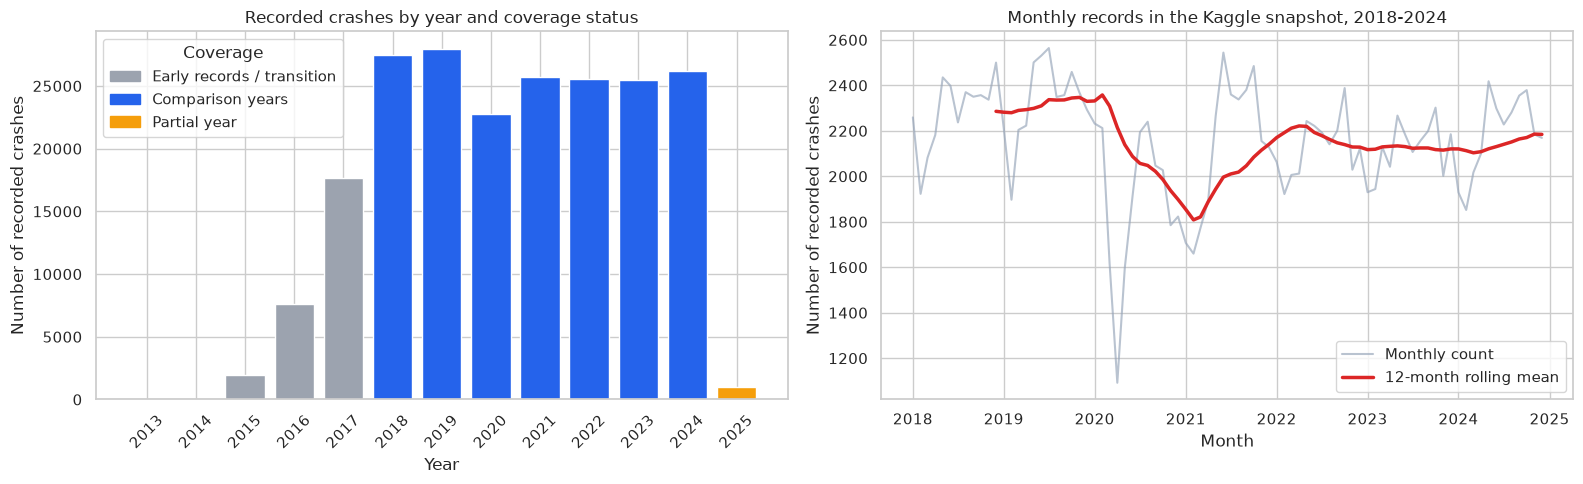

In [17]:
coverage_colors = {
    "Early records / transition": "#9CA3AF",
    "Comparison years": "#2563EB",
    "Partial year": "#F59E0B",
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

bar_colors = yearly_counts["coverage_status"].map(coverage_colors)
axes[0].bar(yearly_counts.index.astype(str), yearly_counts["crash_count"], color=bar_colors)
axes[0].set_title("Recorded crashes by year and coverage status")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of recorded crashes")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(
    handles=[Patch(color=color, label=label) for label, color in coverage_colors.items()],
    title="Coverage",
)

axes[1].plot(monthly_counts.index, monthly_counts["crash_count"], color="#94A3B8", alpha=0.65, label="Monthly count")
axes[1].plot(monthly_counts.index, monthly_counts["12_month_rolling_mean"], color="#DC2626", linewidth=2.5, label="12-month rolling mean")
axes[1].set_title("Monthly records in the Kaggle snapshot, 2018-2024")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of recorded crashes")
axes[1].legend()

plt.tight_layout()
plt.show()

The 2018-2024 window contains 181,051 records, with a maximum of 27,957 in 2019. The 2020 count was 22,777. Changes in traffic volume, reporting, or snapshot selection could all affect these counts.

### 4.2 Numerical distributions, ranges, and outliers

The most relevant numerical variables are the number of involved units and the injury counts. Because these are non-negative event counts with many zeros, their distributions are expected to be right-skewed. The IQR rule is used as a flag for inspection, not as an automatic deletion rule: a rare multi-vehicle or high-injury crash can be unusual without being erroneous.

In [18]:
event_count_columns = [
    "num_units",
    "injuries_total",
    "injuries_fatal",
    "injuries_incapacitating",
    "injuries_non_incapacitating",
    "injuries_reported_not_evident",
    "injuries_no_indication",
]

numerical_profile = clean_df[event_count_columns].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
).T
display(numerical_profile)

outlier_records = []
for column in event_count_columns:
    q1 = clean_df[column].quantile(0.25)
    q3 = clean_df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    flagged = ((clean_df[column] < lower_bound) | (clean_df[column] > upper_bound)).sum()
    outlier_records.append({
        "column": column,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "flagged_rows": int(flagged),
        "flagged_percentage": round(flagged / len(clean_df) * 100, 3),
    })

outlier_summary = pd.DataFrame(outlier_records).set_index("column")
display(outlier_summary)

,count,mean,std,min,25%,50%,75%,95%,99%,max
num_units,209275.0,2.063299,0.396030,1.0,2.0,2.0,2.0,3.0,4.0,11.0
injuries_total,209275.0,0.382707,0.799720,0.0,0.0,0.0,1.0,2.0,4.0,21.0
injuries_fatal,209275.0,0.001859,0.047505,0.0,0.0,0.0,0.0,0.0,0.0,3.0
injuries_incapacitating,209275.0,0.038103,0.233971,0.0,0.0,0.0,0.0,0.0,1.0,7.0
injuries_non_incapacitating,209275.0,0.221226,0.614939,0.0,0.0,0.0,0.0,1.0,3.0,21.0
injuries_reported_not_evident,209275.0,0.121520,0.450884,0.0,0.0,0.0,0.0,1.0,2.0,15.0
injuries_no_indication,209275.0,2.244019,1.241159,0.0,2.0,2.0,3.0,4.0,6.0,49.0


,q1,q3,iqr,lower_bound,upper_bound,flagged_rows,flagged_percentage
column,,,,,,,
num_units,2.0,2.0,0.0,2.0,2.0,19938,9.527
injuries_total,0.0,1.0,1.0,-1.5,2.5,5691,2.719
injuries_fatal,0.0,0.0,0.0,0.0,0.0,351,0.168
injuries_incapacitating,0.0,0.0,0.0,0.0,0.0,6633,3.170
injuries_non_incapacitating,0.0,0.0,0.0,0.0,0.0,32994,15.766
injuries_reported_not_evident,0.0,0.0,0.0,0.0,0.0,18684,8.928
injuries_no_indication,2.0,3.0,1.0,0.5,4.5,16219,7.750


In [19]:
injury_component_columns = [
    "injuries_fatal",
    "injuries_incapacitating",
    "injuries_non_incapacitating",
    "injuries_reported_not_evident",
]

numerical_validity = pd.Series({
    "negative_event_counts": int((clean_df[event_count_columns] < 0).sum().sum()),
    "num_units_below_one": int((clean_df["num_units"] < 1).sum()),
    "injury_component_sum_mismatches": int(
        (clean_df["injuries_total"] != clean_df[injury_component_columns].sum(axis=1)).sum()
    ),
    "maximum_num_units": int(clean_df["num_units"].max()),
    "maximum_injuries_total": int(clean_df["injuries_total"].max()),
})
display(numerical_validity.to_frame("value"))

,value
negative_event_counts,0
num_units_below_one,0
injury_component_sum_mismatches,0
maximum_num_units,11
maximum_injuries_total,21


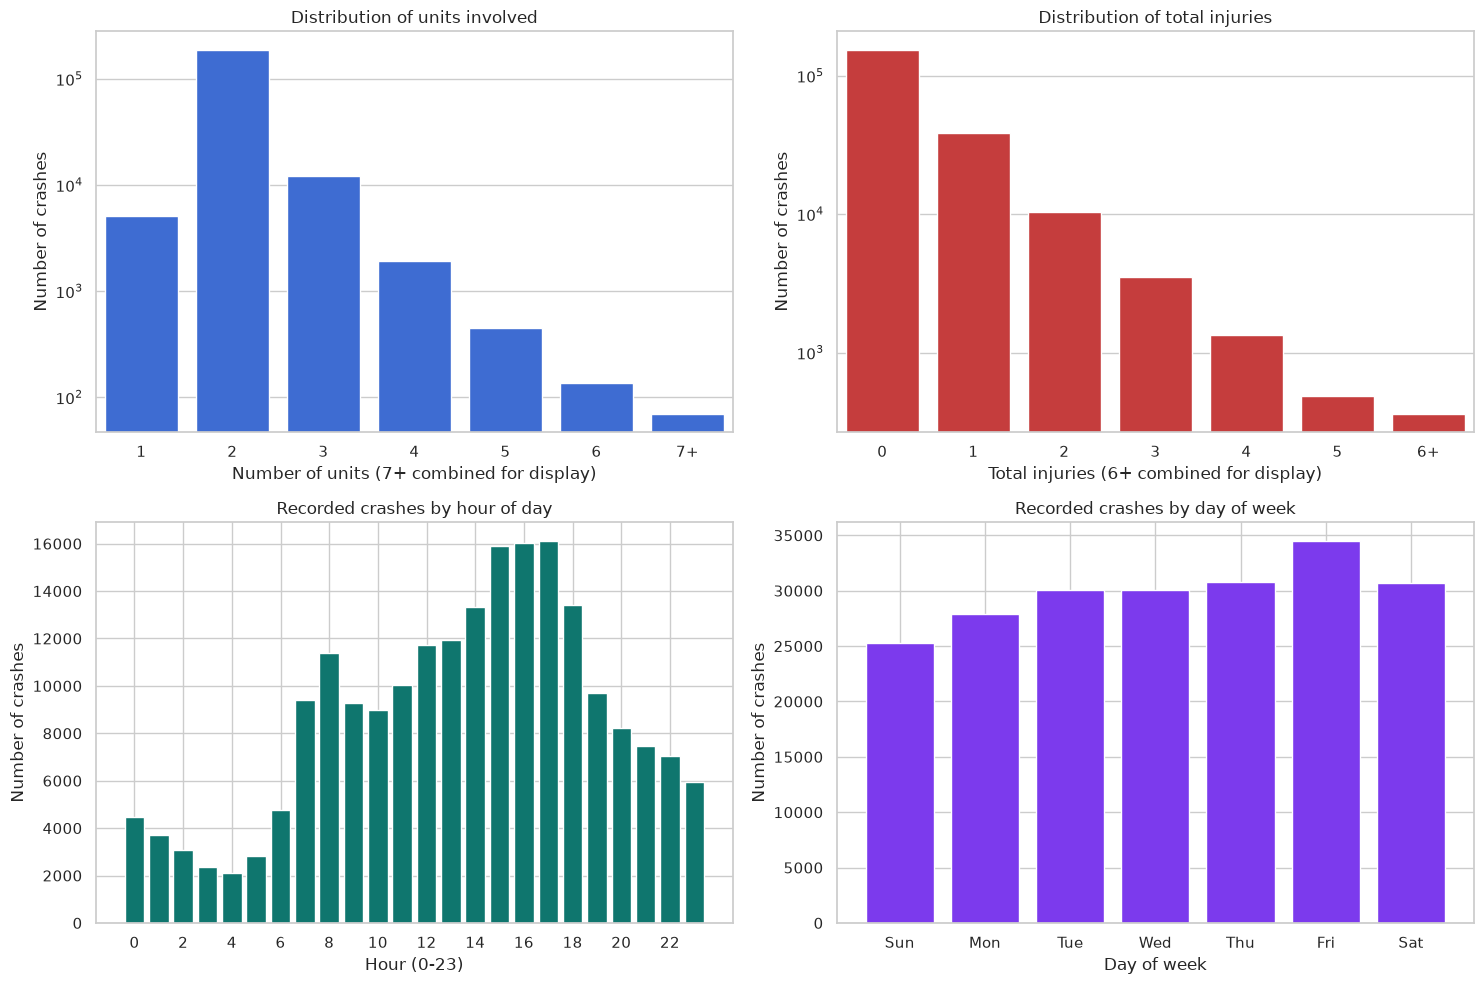

In [20]:
num_units_plot = clean_df["num_units"].where(clean_df["num_units"] <= 6, "7+").astype(str)
num_units_order = ["1", "2", "3", "4", "5", "6", "7+"]

injuries_plot = clean_df["injuries_total"].where(clean_df["injuries_total"] <= 5, "6+").astype(str)
injuries_order = ["0", "1", "2", "3", "4", "5", "6+"]

weekday_labels = {1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"}
weekday_counts = clean_df["crash_day_of_week"].map(weekday_labels).value_counts().reindex(weekday_labels.values())

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.countplot(x=num_units_plot, order=num_units_order, color="#2563EB", ax=axes[0, 0])
axes[0, 0].set_title("Distribution of units involved")
axes[0, 0].set_xlabel("Number of units (7+ combined for display)")
axes[0, 0].set_ylabel("Number of crashes")
axes[0, 0].set_yscale("log")

sns.countplot(x=injuries_plot, order=injuries_order, color="#DC2626", ax=axes[0, 1])
axes[0, 1].set_title("Distribution of total injuries")
axes[0, 1].set_xlabel("Total injuries (6+ combined for display)")
axes[0, 1].set_ylabel("Number of crashes")
axes[0, 1].set_yscale("log")

hourly_counts = clean_df["crash_hour"].value_counts().sort_index()
axes[1, 0].bar(hourly_counts.index, hourly_counts.values, color="#0F766E")
axes[1, 0].set_title("Recorded crashes by hour of day")
axes[1, 0].set_xlabel("Hour (0-23)")
axes[1, 0].set_ylabel("Number of crashes")
axes[1, 0].set_xticks(range(0, 24, 2))

axes[1, 1].bar(weekday_counts.index, weekday_counts.values, color="#7C3AED")
axes[1, 1].set_title("Recorded crashes by day of week")
axes[1, 1].set_xlabel("Day of week")
axes[1, 1].set_ylabel("Number of crashes")

plt.tight_layout()
plt.show()

Two-unit crashes account for 189,337 records (90.47%). The maximum per record is 11 units or 21 reported injuries. When the middle half of a count distribution is zero, the IQR rule can flag every positive count. All injury totals match the sum of their components, so the shared cleaning retains these records.

### 4.3 Categorical balance and rare labels

The compact audit summarizes every categorical column. Detailed plots are limited to variables most relevant to the planned questions. `Other` in a plot is only a display grouping for labels outside the most frequent categories; it does not modify the stored data.

In [21]:
clean_object_columns = clean_df.select_dtypes(include=["object", "string"]).columns
categorical_records = []

for column in clean_object_columns:
    counts = clean_df[column].value_counts(dropna=False)
    normalized = clean_df[column].astype("string").str.strip().str.upper()
    categorical_records.append({
        "column": column,
        "distinct_values": clean_df[column].nunique(dropna=False),
        "top_value": counts.index[0],
        "top_count": int(counts.iloc[0]),
        "top_percentage": round(counts.iloc[0] / len(clean_df) * 100, 2),
        "labels_below_0.1pct": int((counts / len(clean_df) < 0.001).sum()),
        "raw_to_normalized_label_difference": int(clean_df[column].nunique() - normalized.nunique()),
    })

categorical_profile = pd.DataFrame(categorical_records).set_index("column")
display(categorical_profile)

,distinct_values,top_value,top_count,top_percentage,labels_below_0.1pct,raw_to_normalized_label_difference
column,,,,,,
traffic_control_device,19,TRAFFIC SIGNAL,123923,59.22,12,0
weather_condition,12,CLEAR,164673,78.69,3,0
lighting_condition,6,DAYLIGHT,134083,64.07,0,0
first_crash_type,18,TURNING,64150,30.65,4,0
trafficway_type,20,NOT DIVIDED,77737,37.15,3,0
alignment,6,STRAIGHT AND LEVEL,204561,97.75,2,0
roadway_surface_cond,7,DRY,155878,74.48,1,0
road_defect,7,NO DEFECTS,171702,82.05,1,0
crash_type,2,NO INJURY / DRIVE AWAY,117356,56.08,0,0


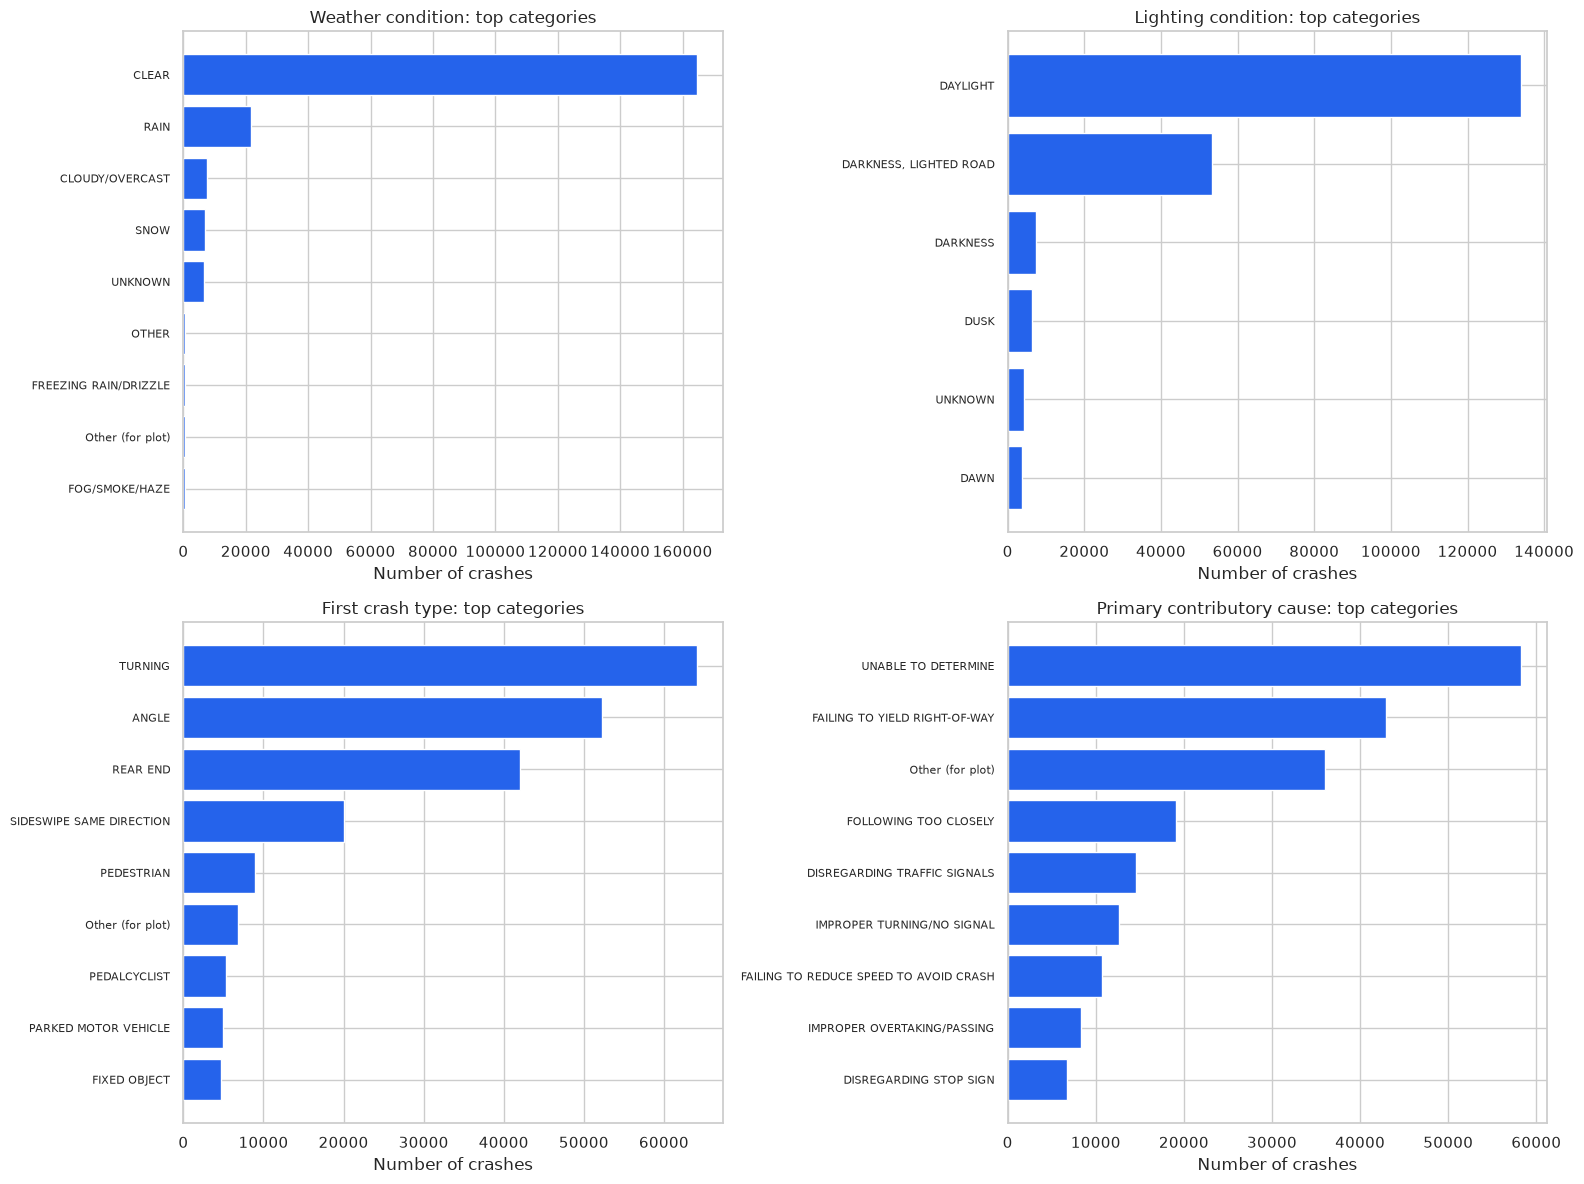

In [22]:
def plot_top_categories(ax, data, column, title, n=8):
    counts = data[column].value_counts()
    top_labels = counts.head(n).index
    display_values = data[column].where(data[column].isin(top_labels), "Other (for plot)")
    plot_counts = display_values.value_counts().sort_values()
    ax.barh(plot_counts.index, plot_counts.values, color="#2563EB")
    ax.set_title(title)
    ax.set_xlabel("Number of crashes")
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=8)


fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plot_top_categories(axes[0, 0], clean_df, "weather_condition", "Weather condition: top categories")
plot_top_categories(axes[0, 1], clean_df, "lighting_condition", "Lighting condition: top categories")
plot_top_categories(axes[1, 0], clean_df, "first_crash_type", "First crash type: top categories")
plot_top_categories(axes[1, 1], clean_df, "prim_contributory_cause", "Primary contributory cause: top categories")

plt.tight_layout()
plt.show()

`CLEAR` (78.69%) and `DAYLIGHT` (64.07%) dominate their respective fields. The most frequent value for reported primary cause is `UNABLE TO DETERMINE` (27.86%). The processed file retains rare categories and groups them only in the display where indicated.

### 4.4 Conventional missingness, placeholders, and label consistency

The audit counts conventional nulls, blank strings, and explicit placeholders separately. `UNKNOWN` and `UNABLE TO DETERMINE` indicate unavailable or unresolved values, while `NOT APPLICABLE` can represent a field that does not apply. The following table also checks whether the combined placeholder flag is equally common among records with and without a reported injury.

In [23]:
placeholder_values = {"UNKNOWN", "NOT APPLICABLE", "UNABLE TO DETERMINE"}
quality_records = []

for column in clean_df.columns:
    series = clean_df[column]
    is_text = column in clean_object_columns
    blank_count = 0
    placeholder_count = 0
    if is_text:
        normalized = series.astype("string").str.strip().str.upper()
        blank_count = int((series.notna() & normalized.eq("")).sum())
        placeholder_count = int(normalized.isin(placeholder_values).sum())
    quality_records.append({
        "column": column,
        "conventional_missing_count": int(series.isna().sum()),
        "blank_count": blank_count,
        "placeholder_count": placeholder_count,
        "placeholder_percentage": round(placeholder_count / len(clean_df) * 100, 2),
    })

data_quality_table = pd.DataFrame(quality_records).set_index("column")
display(data_quality_table.loc[(data_quality_table != 0).any(axis=1)])

placeholder_mask = clean_df[clean_object_columns].apply(
    lambda series: series.astype("string").str.strip().str.upper().isin(placeholder_values)
)
has_placeholder = placeholder_mask.any(axis=1)
rows_with_placeholder = has_placeholder.sum()
print(f"Rows containing at least one placeholder: {rows_with_placeholder:,} ({rows_with_placeholder / len(clean_df) * 100:.2f}%)")

placeholder_by_injury = has_placeholder.groupby(clean_df["has_injury"]).agg(
    crash_count="size", crashes_with_placeholder="sum"
)
placeholder_by_injury["placeholder_pct"] = (
    100 * placeholder_by_injury["crashes_with_placeholder"] / placeholder_by_injury["crash_count"]
).round(2)
display(placeholder_by_injury)

,conventional_missing_count,blank_count,placeholder_count,placeholder_percentage
column,,,,
traffic_control_device,0,0,4455,2.13
weather_condition,0,0,6534,3.12
lighting_condition,0,0,4336,2.07
trafficway_type,0,0,1060,0.51
roadway_surface_cond,0,0,12509,5.98
road_defect,0,0,34423,16.45
prim_contributory_cause,0,0,63551,30.37


Rows containing at least one placeholder: 84,400 (40.33%)


,crash_count,crashes_with_placeholder,placeholder_pct
has_injury,,,
False,154767,64839,41.89
True,54508,19561,35.89


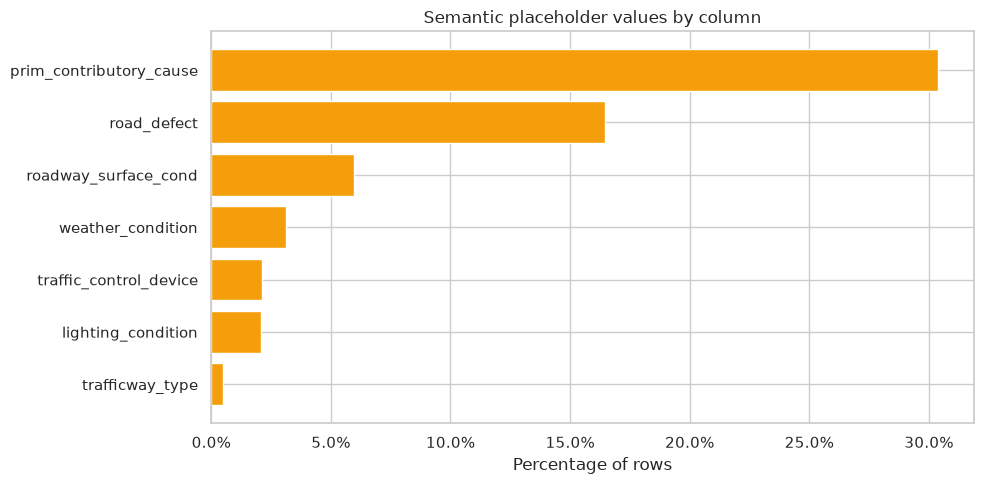

In [24]:
placeholder_plot = (
    data_quality_table.loc[data_quality_table["placeholder_count"] > 0, ["placeholder_percentage"]]
    .sort_values("placeholder_percentage")
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(placeholder_plot.index, placeholder_plot["placeholder_percentage"], color="#F59E0B")
ax.set_title("Semantic placeholder values by column")
ax.set_xlabel("Percentage of rows")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
plt.tight_layout()
plt.show()

At least one placeholder appears in 41.89% of records without a reported injury and 35.89% of records with one. The fields with the highest placeholder shares are `prim_contributory_cause` (30.37%) and `road_defect` (16.45%). A blanket exclusion would remove different shares of the two injury groups, so the shared file retains the original labels.

### 4.5 Relationships among variables relevant to the questions

The following grouped summaries compare injury and severe-injury proportions across selected contextual variables. Groups with fewer than 500 records are omitted from the plots to avoid visually emphasizing unstable tiny groups, but the stored data are unchanged. These are descriptive associations, not causal effects: weather, lighting, road type, collision type, exposure, and reporting practices may be related to one another.

In [25]:
def injury_relationship_summary(data, column, minimum_count=500):
    summary = (
        data.groupby(column, observed=False)
        .agg(
            crashes=("has_injury", "size"),
            injury_crashes=("has_injury", "sum"),
            severe_injury_crashes=("has_severe_injury", "sum"),
        )
    )
    summary["injury_rate_pct"] = summary["injury_crashes"] / summary["crashes"] * 100
    summary["severe_injury_rate_pct"] = summary["severe_injury_crashes"] / summary["crashes"] * 100
    return summary.loc[summary["crashes"] >= minimum_count].sort_values("injury_rate_pct", ascending=False)


relationship_columns = [
    "weather_condition",
    "lighting_condition",
    "first_crash_type",
    "intersection_related_i",
]

relationship_tables = {
    column: injury_relationship_summary(clean_df, column)
    for column in relationship_columns
}

for column, table in relationship_tables.items():
    print(f"\nInjury outcomes by {column} (groups with at least 500 crashes)")
    display(table.round(2))

print("Lighting conditions by time period (% within each period)")
lighting_by_period = pd.crosstab(
    clean_df["time_period"], clean_df["lighting_condition"], normalize="index"
).mul(100)
display(lighting_by_period.round(2))


Injury outcomes by weather_condition (groups with at least 500 crashes)


,crashes,injury_crashes,severe_injury_crashes,injury_rate_pct,severe_injury_rate_pct
weather_condition,,,,,
OTHER,627,204,29,32.54,4.63
FREEZING RAIN/DRIZZLE,510,160,16,31.37,3.14
RAIN,21702,6180,708,28.48,3.26
CLEAR,164673,43405,5682,26.36,3.45
CLOUDY/OVERCAST,7532,1974,225,26.21,2.99
SNOW,6869,1499,140,21.82,2.04
UNKNOWN,6534,849,92,12.99,1.41



Injury outcomes by lighting_condition (groups with at least 500 crashes)


,crashes,injury_crashes,severe_injury_crashes,injury_rate_pct,severe_injury_rate_pct
lighting_condition,,,,,
"DARKNESS, LIGHTED ROAD",53375,15718,2207,29.45,4.13
DARKNESS,7436,2064,305,27.76,4.10
DAWN,3723,1026,149,27.56,4.00
DUSK,6322,1636,207,25.88,3.27
DAYLIGHT,134083,33528,3989,25.01,2.98
UNKNOWN,4336,536,57,12.36,1.31



Injury outcomes by first_crash_type (groups with at least 500 crashes)


,crashes,injury_crashes,severe_injury_crashes,injury_rate_pct,severe_injury_rate_pct
first_crash_type,,,,,
PEDESTRIAN,8995,8054,1648,89.54,18.32
PEDALCYCLIST,5335,4027,562,75.48,10.53
HEAD ON,1790,699,113,39.05,6.31
ANGLE,52243,17101,2030,32.73,3.89
OTHER OBJECT,759,247,41,32.54,5.40
FIXED OBJECT,4742,1243,251,26.21,5.29
REAR TO SIDE,773,183,22,23.67,2.85
TURNING,64150,13590,1478,21.18,2.30
SIDESWIPE OPPOSITE DIRECTION,1839,330,49,17.94,2.66



Injury outcomes by intersection_related_i (groups with at least 500 crashes)


,crashes,injury_crashes,severe_injury_crashes,injury_rate_pct,severe_injury_rate_pct
intersection_related_i,,,,,
Y,199294,52521,6634,26.35,3.33
N,9981,1987,280,19.91,2.81


Lighting conditions by time period (% within each period)


lighting_condition,DARKNESS,"DARKNESS, LIGHTED ROAD",DAWN,DAYLIGHT,DUSK,UNKNOWN
time_period,,,,,,
Night,7.52,79.74,4.18,5.24,1.47,1.85
Morning,0.49,2.19,2.63,93.00,0.32,1.37
Afternoon,1.24,5.88,0.88,86.64,3.10,2.26
Evening,9.11,62.54,1.50,18.00,6.26,2.57


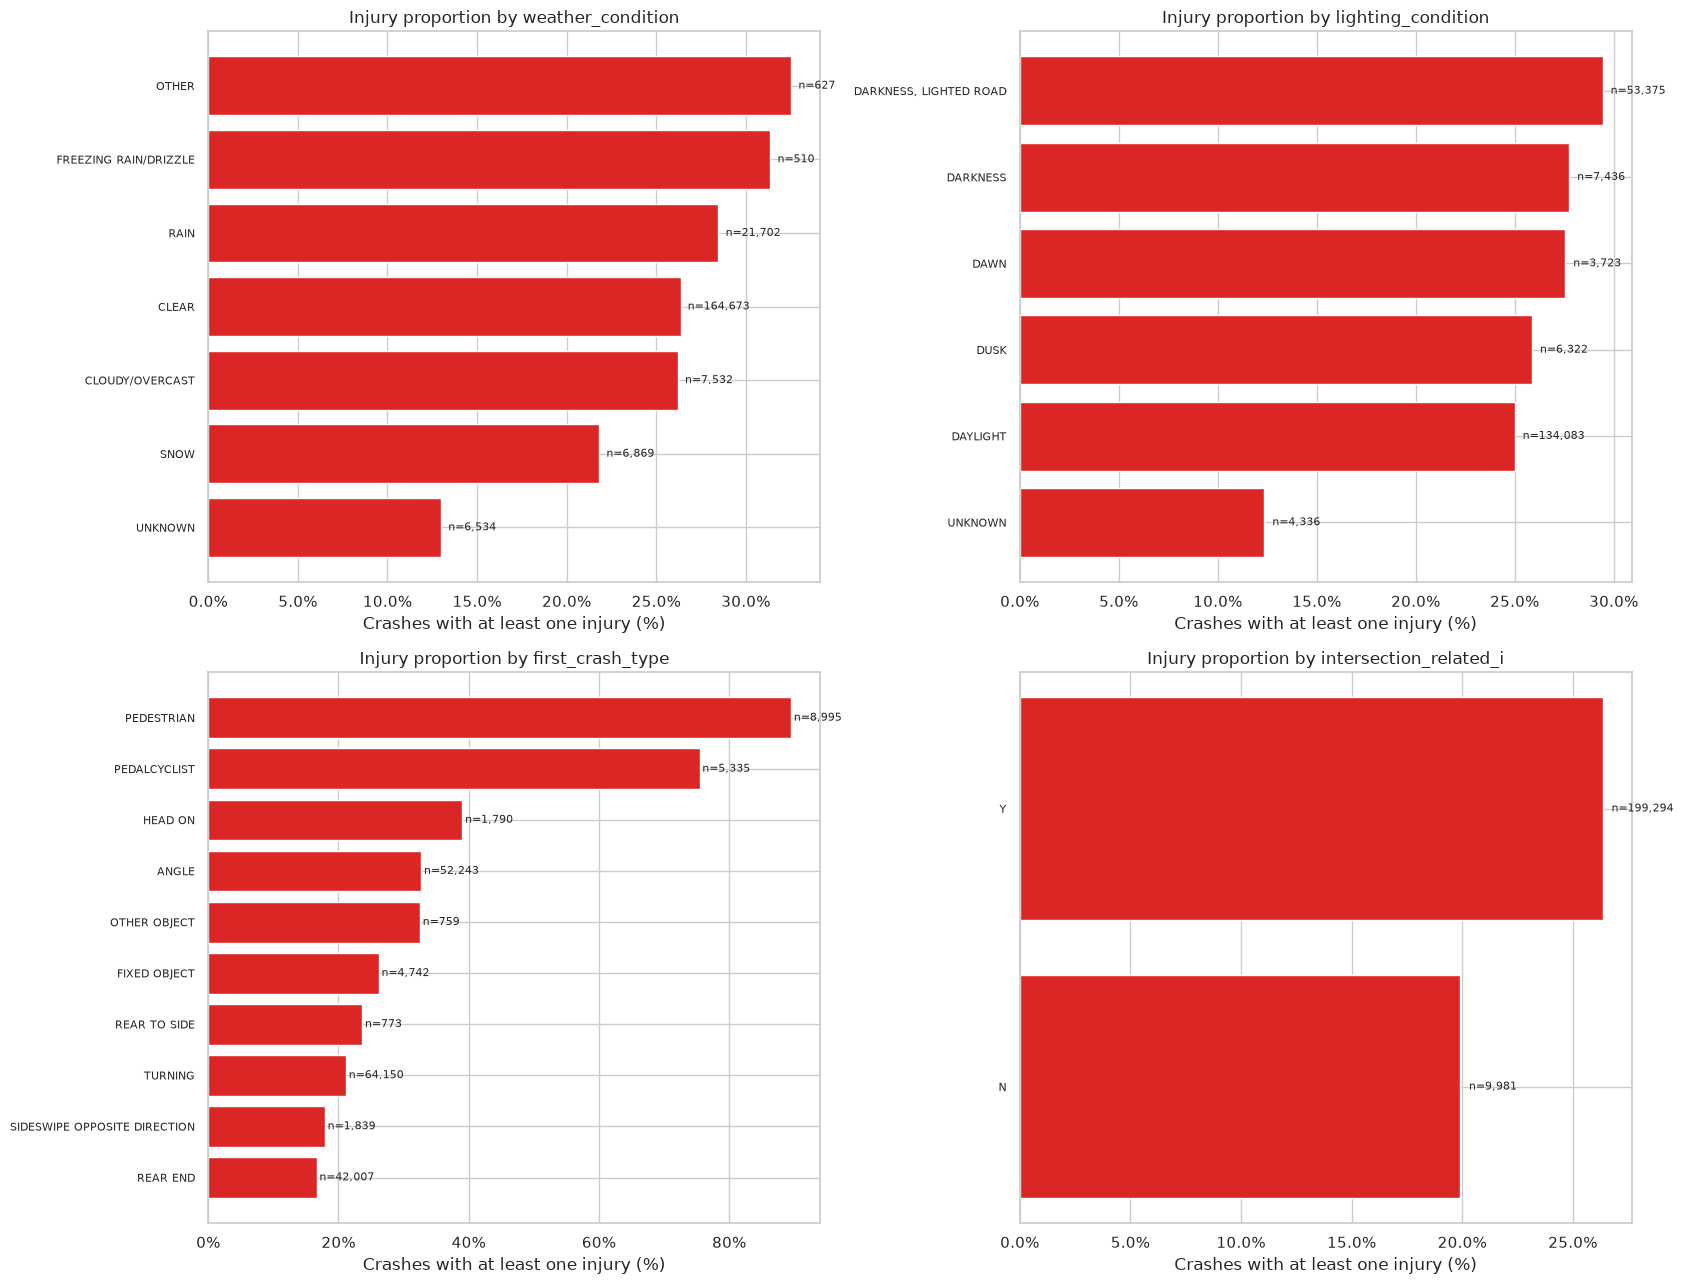

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(17, 13))

for ax, column in zip(axes.flat, relationship_columns):
    table = relationship_tables[column].sort_values("injury_rate_pct").tail(10)
    bars = ax.barh(table.index.astype(str), table["injury_rate_pct"], color="#DC2626")
    ax.set_title(f"Injury proportion by {column}")
    ax.set_xlabel("Crashes with at least one injury (%)")
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=8)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    for bar, count in zip(bars, table["crashes"]):
        ax.text(
            bar.get_width() + 0.4,
            bar.get_y() + bar.get_height() / 2,
            f"n={count:,.0f}",
            va="center",
            fontsize=8,
        )

plt.tight_layout()
plt.show()

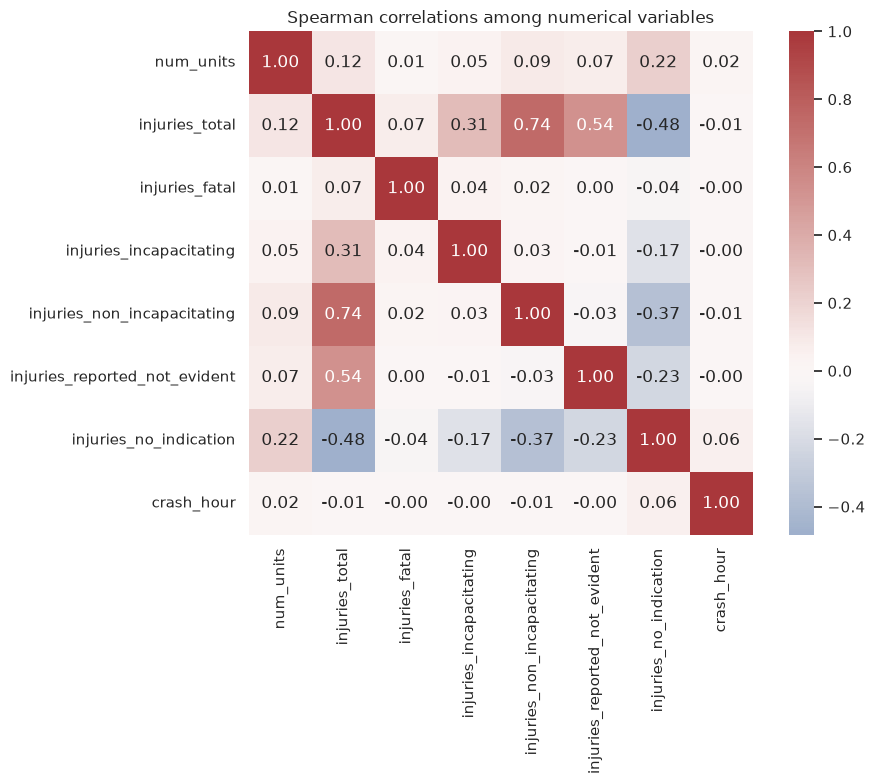

In [27]:
correlation_columns = [
    "num_units",
    "injuries_total",
    "injuries_fatal",
    "injuries_incapacitating",
    "injuries_non_incapacitating",
    "injuries_reported_not_evident",
    "injuries_no_indication",
    "crash_hour",
]

spearman_correlation = clean_df[correlation_columns].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    spearman_correlation,
    cmap="vlag",
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    ax=ax,
)
ax.set_title("Spearman correlations among numerical variables")
plt.tight_layout()
plt.show()

Reported injury appears in 89.54% of pedestrian and 75.48% of pedal-cyclist first-crash records, compared with 26.05% overall. Evening records are predominantly classified as `DARKNESS, LIGHTED ROAD` (62.54%), while 86.64% of afternoon records are classified as `DAYLIGHT`. These percentages are conditional on a crash being included in the snapshot. Correlations between injury counts and their components partly reflect how the total is computed.

### 4.6 Reproducibility and processed-data checks

The notebook validates the row count, schema, date type, and injury counts before exporting the cleaned CSV.

In [28]:
expected_derived_columns = {
    "crash_year",
    "has_injury",
    "has_severe_injury",
    "is_weekend",
    "time_period",
}

assert clean_df.duplicated().sum() == 0
assert clean_df.isna().sum().sum() == 0
assert pd.api.types.is_datetime64_any_dtype(clean_df["crash_date"])
assert expected_derived_columns.issubset(clean_df.columns)
assert (clean_df[event_count_columns] >= 0).all().all()
assert (clean_df["num_units"] >= 1).all()
assert (clean_df["injuries_total"] == clean_df[injury_component_columns].sum(axis=1)).all()
assert len(clean_df) == len(df) - duplicate_count

print("All processed-data checks passed.")
print(f"Verified rows: {len(clean_df):,}")
print(f"Verified columns: {clean_df.shape[1]}")

PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
clean_df.to_csv(PROCESSED_DATA_PATH, index=False)
print(f"Processed data saved to: {PROCESSED_DATA_PATH.relative_to(PROJECT_ROOT)}")

All processed-data checks passed.
Verified rows: 209,275
Verified columns: 29


Processed data saved to: data/processed/traffic_accidents_clean.csv


## 5. Exploration summary and preprocessing plan

### 5.1 Evidence summary

The following compact table collects the exact values needed for the written summary. It is generated from the current data so that the narrative can be checked against the notebook output.

In [29]:
peak_complete_year = int(
    yearly_counts.loc[yearly_counts.index.to_series().between(2018, 2024), "crash_count"].idxmax()
)

summary_evidence = pd.Series({
    "raw_rows": len(df),
    "processed_rows": len(clean_df),
    "duplicates_removed": duplicate_count,
    "conventional_missing_values": int(clean_df.isna().sum().sum()),
    "rows_with_at_least_one_placeholder_pct": round(rows_with_placeholder / len(clean_df) * 100, 2),
    "complete_comparison_rows_2018_2024": len(complete_year_df),
    "peak_complete_year": peak_complete_year,
    "peak_complete_year_crashes": int(yearly_counts.loc[peak_complete_year, "crash_count"]),
    "crashes_with_injury_pct": round(clean_df["has_injury"].mean() * 100, 2),
    "crashes_with_severe_injury_pct": round(clean_df["has_severe_injury"].mean() * 100, 2),
    "two_unit_crashes_pct": round(clean_df["num_units"].eq(2).mean() * 100, 2),
    "maximum_injuries_total": int(clean_df["injuries_total"].max()),
})
display(summary_evidence.to_frame("value"))

,value
raw_rows,209306.00
processed_rows,209275.00
duplicates_removed,31.00
conventional_missing_values,0.00
rows_with_at_least_one_placeholder_pct,40.33
complete_comparison_rows_2018_2024,181051.00
peak_complete_year,2019.00
peak_complete_year_crashes,27957.00
crashes_with_injury_pct,26.05
crashes_with_severe_injury_pct,3.30


### 5.2 Key exploration findings

1. **Time coverage.** The snapshot contains 181,051 cleaned records from 2018 through 2024. The largest annual count in that window is 27,957 in 2019. That window avoids the early coverage transition and partial 2025 data. The counts apply to the Kaggle snapshot, whose selection process and traffic exposure are unknown.
2. **Duplicate and date checks.** Removing 31 exact duplicate rows leaves 209,275 records. All timestamps parse and agree with their supplied hour, weekday, and month. The lack of a crash identifier limits verification of duplicate events.
3. **Unavailable information.** There are zero conventional nulls. Explicit placeholders occur in 84,400 records (40.33%) and are more common among crashes without a reported injury. Retaining those categories avoids a blanket exclusion that would affect the injury groups differently.
4. **Injury and unit counts.** Two-unit crashes make up 90.47% of the data. At least one injury is reported in 26.05% of records, and 3.30% have a fatal or incapacitating injury. Rare count values remain because the checks found no negative counts or inconsistent injury totals.
5. **Differences worth examining.** The lighting composition varies substantially between afternoon and evening. The injury share also differs across collision types. These patterns help motivate the follow-up questions, where the comparison groups and their limitations can be examined explicitly.

LLM assistance with the exploratory code and wording is documented in `LLM_USAGE.md`.

### 5.3 Shared preprocessing decisions

- Preserve the raw CSV unchanged in `data/raw/`.
- Remove 31 exact duplicate rows for the shared processed dataset and retain a raw-data robustness path for questions affected by this choice.
- Parse `crash_date` with an explicit format and verify its hour, weekday, and month against the supplied columns.
- Convert injury counts to integer event counts.
- Add `crash_year`, `has_injury`, `has_severe_injury`, `is_weekend`, and `time_period` as documented derived variables.
- Preserve semantic placeholders as explicit categories; document and count any question-specific filtering or regrouping.
- Save the reproducible shared result to `data/processed/traffic_accidents_clean.csv`; do not commit large raw or processed files to Git.

### 5.4 Link to the analytical questions

The temporal coverage and monthly patterns support full-year and intervention-period comparisons such as Q1. The joint structure of time and lighting supports the DST-related Q2 after merging a documented external DST calendar. The environmental, road, collision, and injury variables support the other members' descriptive and machine-learning questions. Each later notebook must state its exact question, report row counts after every filter or merge, quantify uncertainty where required, include at least two labelled plots, and discuss limitations.

